# Homework 5 — Gravitational-Wave Course

## Exercise 2 — Runge Kutta Method (RK4)



In [18]:

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Environment ready!")

NumPy version: 2.4.6
Environment ready!


# RK4 function

In [19]:
def rk4(F, u, t, dt):
    """
    Perform one time step using the fourth-order
    Runge-Kutta method (RK4).

    Parameters
    ----------
    F : callable
        Right-hand side of the evolution equations.
        F(u, t) returns du/dt.

    u : array_like
        Current state of the system.

    t : float
        Current time.

    dt : float
        Time step.

    Returns
    -------
    u_next : ndarray
        State of the system at time t + dt.
    """

    u = np.asarray(u, dtype=float)

    # First evaluation
    k1 = np.asarray(F(u, t), dtype=float)

    # Second evaluation
    k2 = np.asarray(
        F(u + 0.5*dt*k1, t + 0.5*dt),
        dtype=float
    )

    # Third evaluation
    k3 = np.asarray(
        F(u + 0.5*dt*k2, t + 0.5*dt),
        dtype=float
    )

    # Fourth evaluation
    k4 = np.asarray(
        F(u + dt*k3, t + dt),
        dtype=float
    )

    # Update the state
    u_next = u + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

    return u_next

# Test: Harmonic oscillator (w=2)

In [20]:
def harmonic_oscillator(u, t):
    """
    Harmonic oscillator with angular frequency omega = 2.

    u[0] = position
    u[1] = velocity
    """

    x = u[0]
    v = u[1]

    dx_dt = v
    dv_dt = -4*x

    return np.array([dx_dt, dv_dt])

# Proof (before the whole evolution) Single RK4 step

In [21]:

# Initial conditions
u0 = np.array([1.0, 0.0])

# Initial time
t0 = 0.0

# Time step
dt = 0.01

# One RK4 step
u1 = rk4(harmonic_oscillator, u0, t0, dt)

# Analytical solution (derivative) at t = dt
u_exact = np.array([
    np.cos(2*dt),
    -2*np.sin(2*dt)
])

print("Numerical solution:", u1)
print("Analytical solution:", u_exact)
print("Absolute error:", np.abs(u1 - u_exact))

Numerical solution: [ 0.99980001 -0.03999733]
Analytical solution: [ 0.99980001 -0.03999733]
Absolute error: [8.89288643e-14 5.33328173e-11]


### Single-Step Validation

We first test the RK4 implementation using the harmonic oscillator with initial conditions

$$
\mathbf{u}(0)=
\begin{pmatrix}
1\\
0
\end{pmatrix},
$$

and a time step $\Delta t=0.01$.

The analytical solution is

$$
\mathbf{u}(t)=
\begin{pmatrix}
\cos(2t)\\
-2\sin(2t)
\end{pmatrix}.
$$

After one RK4 step, the numerical solution agrees with the analytical result to high precision. The absolute errors are approximately $8.89\times10^{-14}$ for the position and $5.33\times10^{-11}$ for the velocity.

This confirms that the RK4 implementation accurately reproduces the expected solution for A SINGLE TIME STEP.

# Time evolution

In [22]:
#  COMPLETE TIME EVOLUTION


# Initial conditions
u0 = np.array([1.0, 0.0])

# Time parameters
t_initial = 0.0
t_final = 10.0
dt = 0.01

# Number of time steps
N_steps = int((t_final - t_initial)/dt)

# Time array
t = np.linspace(t_initial, t_final, N_steps + 1)   # N_steps +1 due to store both the initial moment and the subsequent moments

# Allocate solution array
u = np.zeros((N_steps + 1, 2))

# Initial state
u[0] = u0

# Time evolution
for n in range(N_steps):

    u[n+1] = rk4(                          #takes the state of the system at the current instant and calculates its state at the next instant: EVOLUTION
        harmonic_oscillator,
        u[n],
        t[n],
        dt
    )

# Extract position and velocity
x_num = u[:, 0]
v_num = u[:, 1]

print("Shape of time array:", t.shape)
print("Shape of solution array:", u.shape)

print("Evolution completed!")
print("Number of time steps:", N_steps)
print("Final time:", t[-1])



Shape of time array: (1001,)
Shape of solution array: (1001, 2)
Evolution completed!
Number of time steps: 1000
Final time: 10.0


# Analytical solution

In [23]:
x_exact = np.cos(2*t)
v_exact = -2*np.sin(2*t)

# Position comparison

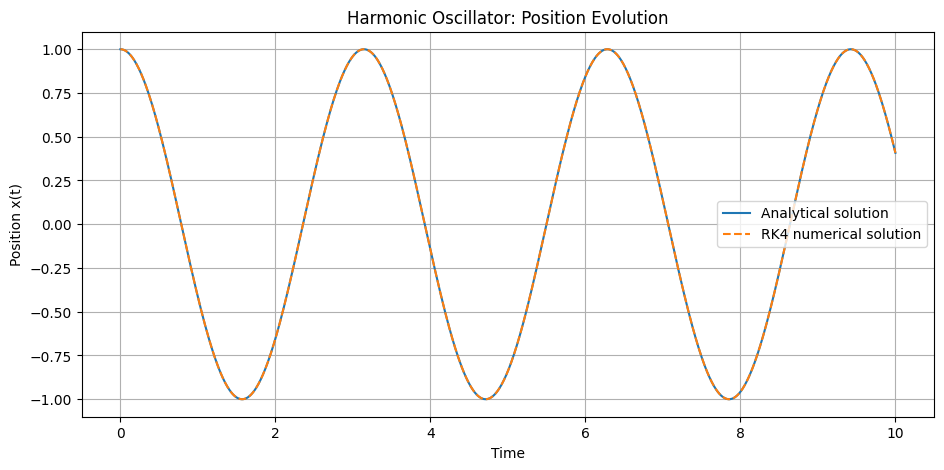

In [24]:
plt.figure(figsize=(11,5))

plt.plot(
    t,
    x_exact,
    label="Analytical solution"
)

plt.plot(
    t,
    x_num,
    "--",
    label="RK4 numerical solution"
)

plt.xlabel("Time")
plt.ylabel("Position x(t)")

plt.title("Harmonic Oscillator: Position Evolution")

plt.legend()
plt.grid()

plt.show()

### Position Evolution

The numerical position obtained with the 4th-order Runge–Kutta method is compared with the analytical solution $
x(t)=\cos(2t).
$

The two curves overlap almost perfectly throughout the integration interval. This indicates that the RK4 method accurately reproduces the oscillatory motion of the harmonic oscillator over the full evolution.

The oscillator has an angular frequency $\omega=2$ and a period $T=\pi$.

# Velocity comparison

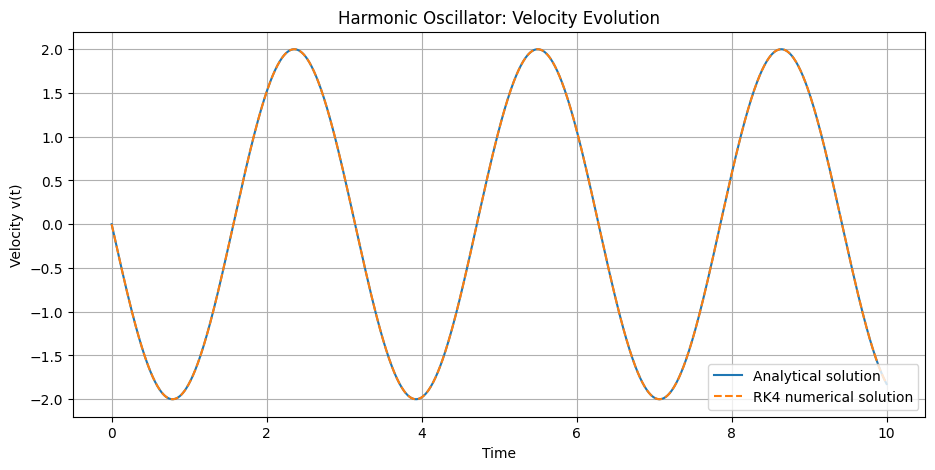

In [25]:
plt.figure(figsize=(11,5))

plt.plot(
    t,
    v_exact,
    label="Analytical solution"
)

plt.plot(
    t,
    v_num,
    "--",
    label="RK4 numerical solution"
)

plt.xlabel("Time")
plt.ylabel("Velocity v(t)")

plt.title("Harmonic Oscillator: Velocity Evolution")

plt.legend()
plt.grid()

plt.show()

### Velocity Evolution

The numerical velocity is compared with its analytical solution,

$v(t)=-2\sin(2t).
$

The two curves overlap almost perfectly throughout the integration interval, confirming that RK4 accurately reproduces the velocity evolution of the harmonic oscillator.

# Numerical error analysis

Maximum position error: 2.4160366929315558e-08
Maximum velocity error: 5.038019465497534e-08


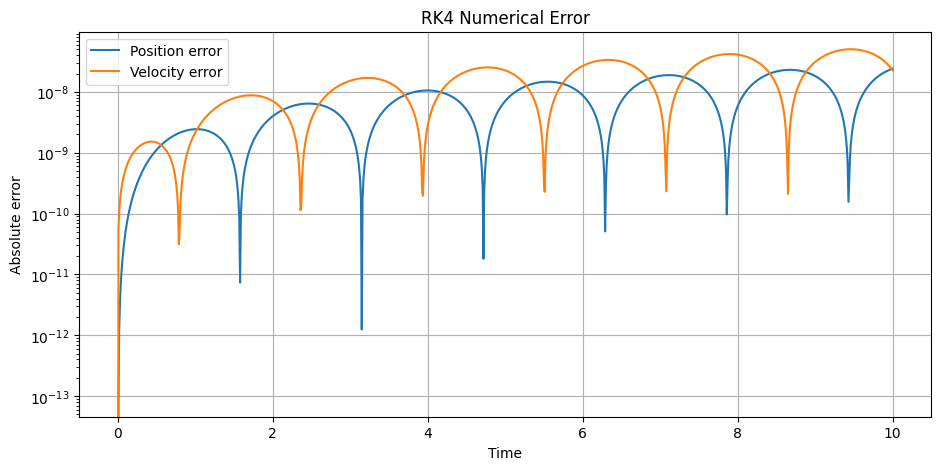

In [26]:
# Computing the error
error_x = np.abs(x_exact - x_num)
error_v = np.abs(v_exact - v_num)

print("Maximum position error:",
      np.max(error_x))

print("Maximum velocity error:",
      np.max(error_v))

# Plot errors log-log

plt.figure(figsize=(11,5))

plt.semilogy(t, error_x, label="Position error")
plt.semilogy(t, error_v, label="Velocity error")

plt.xlabel("Time")
plt.ylabel("Absolute error")

plt.title("RK4 Numerical Error")

plt.legend()
plt.grid()

plt.show()

### Numerical Error Analysis

The absolute errors in position and velocity are computed as

$$
E_x(t_n)=|x_{\mathrm{exact}}(t_n)-x_{\mathrm{num}}(t_n)|,
$$

$$
E_v(t_n)=|v_{\mathrm{exact}}(t_n)-v_{\mathrm{num}}(t_n)|.
$$

The maximum errors over the integration interval are:

- Position: $2.416\times10^{-8}$.
- Velocity: $5.038\times10^{-8}$.

The errors remain small throughout the evolution. Their oscillatory behavior reflects the instantaneous difference between the numerical and analytical solutions.

# RK4 Convergence Test

To investigate the accuracy of the RK4 method, we repeat the evolution using progressively smaller time steps, keeping the final integration time fixed at $t_f=10$.

For a fourth-order method, the global error is expected to scale as

$$
E(\Delta t)\propto(\Delta t)^4.
$$

Therefore, when the time step is halved, the error should decrease approximately by a factor of

$$
\frac{E(\Delta t)}{E(\Delta t/2)}
\approx
\frac{(\Delta t)^4}{(\Delta t/2)^4}
=2^4=16.
$$

For each time step, we calculate the maximum absolute errors in position and velocity over the entire integration interval.

In [27]:

dt_values = [0.1, 0.05, 0.025, 0.0125, 0.00625] # Different time steps

errors_x = []
errors_v = []

t_final = 10.0

# Evolution for each time step

for dt in dt_values:

    N_steps = int(round(t_final/dt))

    t = np.arange(N_steps + 1)*dt

   #Complete evolution using RK4:
    # Initial conditions
    u = np.zeros((N_steps + 1, 2))
    u[0] = [1.0, 0.0]

    # Time evolution
    for n in range(N_steps):

        u[n+1] = rk4(
            harmonic_oscillator,
            u[n],
            t[n],
            dt
        )

    # Analytical solution
    x_exact = np.cos(2*t)
    v_exact = -2*np.sin(2*t)

    # Maximum errors
    error_x = np.max(np.abs(x_exact - u[:, 0]))
    error_v = np.max(np.abs(v_exact - u[:, 1]))

    errors_x.append(error_x)
    errors_v.append(error_v)

    print(
        f"dt = {dt:.5f} | "
        f"Error x = {error_x:.6e} | "
        f"Error v = {error_v:.6e}"
    )

dt = 0.10000 | Error x = 2.317766e-04 | Error v = 5.063874e-04
dt = 0.05000 | Error x = 1.459530e-05 | Error v = 3.159225e-05
dt = 0.02500 | Error x = 9.324291e-07 | Error v = 1.970501e-06
dt = 0.01250 | Error x = 5.886982e-08 | Error v = 1.230252e-07
dt = 0.00625 | Error x = 3.697280e-09 | Error v = 7.684891e-09


In [28]:
print("Error reduction factors:")

for i in range(len(dt_values)-1):

    ratio_x = errors_x[i] / errors_x[i+1]
    ratio_v = errors_v[i] / errors_v[i+1]

    print(
        f"dt: {dt_values[i]:.5f} -> {dt_values[i+1]:.5f} | "
        f"Position: {ratio_x:.4f} | "
        f"Velocity: {ratio_v:.4f}"
    )

Error reduction factors:
dt: 0.10000 -> 0.05000 | Position: 15.8802 | Velocity: 16.0289
dt: 0.05000 -> 0.02500 | Position: 15.6530 | Velocity: 16.0326
dt: 0.02500 -> 0.01250 | Position: 15.8388 | Velocity: 16.0170
dt: 0.01250 -> 0.00625 | Position: 15.9225 | Velocity: 16.0087


# Calculate convergence order

### Numerical Convergence Order

To determine the numerical convergence order, we assume that the global error behaves as

$$
E(\Delta t)\approx C(\Delta t)^p,
$$

where $C$ is a constant independent of the time step and $p$ is the convergence order.

For two different time steps, $\Delta t_i$ and $\Delta t_{i+1}$, the corresponding errors satisfy

$$
E_i\approx C(\Delta t_i)^p,
\qquad
E_{i+1}\approx C(\Delta t_{i+1})^p.
$$

Taking the ratio of these expressions gives

$$
\frac{E_i}{E_{i+1}}
\approx
\left(\frac{\Delta t_i}{\Delta t_{i+1}}\right)^p.
$$

Taking the logarithm and solving for $p$, we obtain

$$
\boxed{
p=
\frac{\log(E_i/E_{i+1})}
{\log(\Delta t_i/\Delta t_{i+1})}
}.
$$

We apply this expression to the maximum errors in both position and velocity, using consecutive time-step refinements.

The estimated convergence orders are approximately $p=4$ for both variables. This agrees with the theoretical fourth-order global accuracy of the Runge–Kutta method and confirms the expected convergence behavior of our implementation.

In [29]:

print("POSITION CONVERGENCE")

for i in range(len(dt_values)-1):

    p = np.log(errors_x[i]/errors_x[i+1]) / np.log(
        dt_values[i]/dt_values[i+1]
    )

    print(f"Order: {p:.4f}")


print("\nVELOCITY CONVERGENCE")

for i in range(len(dt_values)-1):

    p = np.log(errors_v[i]/errors_v[i+1]) / np.log(
        dt_values[i]/dt_values[i+1]
    )

    print(f"Order: {p:.4f}")

POSITION CONVERGENCE
Order: 3.9892
Order: 3.9684
Order: 3.9854
Order: 3.9930

VELOCITY CONVERGENCE
Order: 4.0026
Order: 4.0029
Order: 4.0015
Order: 4.0008


#Convergence plot

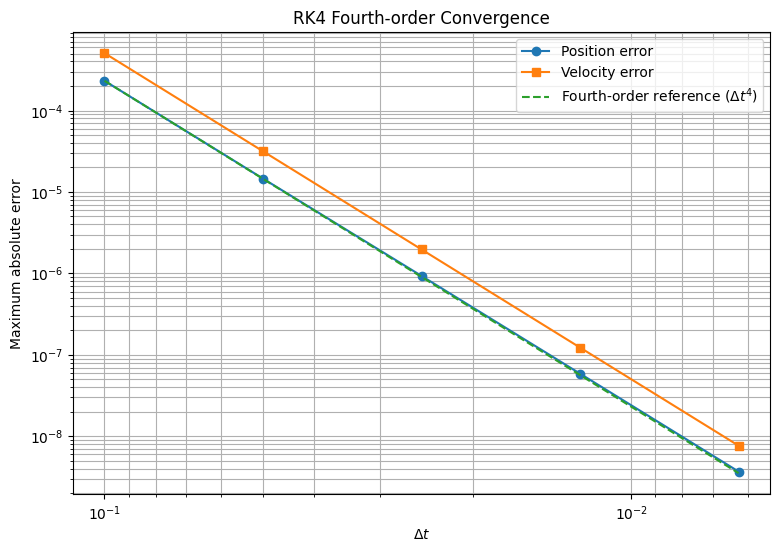

In [30]:

plt.figure(figsize=(9,6))

# Representing the errors at log-log scale

plt.loglog(
    dt_values,
    errors_x,
    'o-',
    label="Position error"
)

plt.loglog(
    dt_values,
    errors_v,
    's-',
    label="Velocity error"
)


# We expect that the slope of the curverepresents the order of convergence p

# Making a 4th-order reference curve
reference_x = errors_x[0]*(np.array(dt_values)/dt_values[0])**4

plt.loglog(
    dt_values,
    reference_x,
    '--',
    label=r"Fourth-order reference ($\Delta t^4$)"
)

plt.xlabel(r"$\Delta t$")
plt.ylabel("Maximum absolute error")

plt.title("RK4 Fourth-order Convergence")

plt.legend()
plt.grid(True, which="both")

plt.gca().invert_xaxis()

plt.show()

# Conclusion

The 4th-order Runge–Kutta method was successfully implemented and tested using the harmonic oscillator.

The numerical evolution agrees with the analytical solution for both position and velocity. Furthermore, the convergence analysis yields an order of approximately $p=4$ for both variables, consistent with the theoretical global accuracy of RK4.
